# 07. Model 3: XGBoost Classifier

**Employee Resignation Prediction Project**  
**Ownership:** Member 3  
**Architecture:** Extreme Gradient Boosting with Histogram Binning  
**Status:** FULLY EXECUTED / PRODUCTION READY

## 1. Objective

Implement, tune, and evaluate **XGBoost (Extreme Gradient Boosting)** on the 5-fold cross-validation development set (80,000 records). XGBoost applies second-order Taylor expansion loss approximations, column subsampling, and histogram-based split finding.

## 2. Reproducibility & Imports

Configure deterministic seeds (`random_state=42`) and set up project paths.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from sklearn.metrics import confusion_matrix, precision_recall_curve

# Resolve repository root
PROJECT_ROOT = Path("../..").resolve()
if not (PROJECT_ROOT / "configs" / "feature_contract.yaml").exists():
    for candidate in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        if (candidate / "configs" / "feature_contract.yaml").exists():
            PROJECT_ROOT = candidate.resolve()
            break

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import calculate_binary_metrics
from src.evaluation.oof_validation import validate_oof_predictions
from src.models.xgboost_model import XGBoostAdapter
from src.models.runner import run_5fold_cv

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "xgboost.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "xgboost"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Results directory: {RESULTS_DIR}")

Project root: C:\Users\USER\Desktop\AIML projects\Employee_Resignation_Prediction
Results directory: C:\Users\USER\Desktop\AIML projects\Employee_Resignation_Prediction\results\models\xgboost


## 3. Load Development Registry & Raw Dataset

Load `Extended_Employee_Performance_and_Productivity_Data.csv` and `split_registry.csv`. Filter strictly to `partition == 'development'` (80,000 records). Formal holdout (20,000 records) is strictly quarantined.

## 4. Validate Feature Contract

Confirm the 17 approved predictors (4 categorical, 13 numerical) match `configs/feature_contract.yaml` exactly.

In [2]:
# Load feature contract
with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as f:
    feature_contract = yaml.safe_load(f)

feature_cols = feature_contract["primary_model_features"]
categorical_cols = [f["name"] for f in feature_contract["categorical_features"]]
numerical_cols = [f["name"] for f in feature_contract["numerical_features"]]
target_col = feature_contract["target"]["column"]
id_col = feature_contract["identifier"]["column"]

print(f"Approved Predictors ({len(feature_cols)} total):")
print(f"  Categorical ({len(categorical_cols)}): {categorical_cols}")
print(f"  Numerical ({len(numerical_cols)}): {numerical_cols}")
print(f"Target Column: {target_col}")

# Load data & split registry
raw_df = pd.read_csv(DATA_PATH)
split_registry = pd.read_csv(SPLIT_PATH)

dev_registry = split_registry[split_registry["partition"] == "development"].copy()
dev_ids = set(dev_registry[id_col])
dev_df = raw_df[raw_df[id_col].isin(dev_ids)].copy()

print(f"Development Dataset Shape: {dev_df.shape}")
print(f"Development Target Prevalence: {dev_df[target_col].mean():.4f} ({dev_df[target_col].sum()} positive / {len(dev_df)} total)")

# Check feature availability
missing_cols = set(feature_cols + [target_col, id_col]) - set(dev_df.columns)
assert not missing_cols, f"Missing required columns in dataset: {missing_cols}"
print("Feature contract validation PASSED.")

Approved Predictors (17 total):
  Categorical (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
  Numerical (13): ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
Target Column: Resigned


Development Dataset Shape: (80000, 20)
Development Target Prevalence: 0.1001 (8008 positive / 80000 total)
Feature contract validation PASSED.


## 5. Model-Specific Preprocessing

`XGBoostAdapter` applies fold-local `OneHotEncoder` to the nominal categorical features (`Department`, `Gender`, `Job_Title`, `Education_Level`) fitted strictly on training fold partitions.

## 6. Hyperparameter Configuration

Load default search space & fixed settings from `configs/models/xgboost.yaml`.

In [3]:
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    xgb_config = yaml.safe_load(f)

print("XGBoost Configuration:")
display(pd.DataFrame(list(xgb_config["fixed_params"].items()), columns=["Parameter", "Value"]))

# Calculate class weight ratio (scale_pos_weight) for imbalance handling
pos_count = (dev_df[target_col] == True).sum()
neg_count = (dev_df[target_col] == False).sum()
scale_pos_weight = float(neg_count / pos_count)
print(f"Calculated scale_pos_weight: {scale_pos_weight:.4f}")

# Defined optimal XGBoost adapter parameters
xgb_params = {
    "n_estimators": 400,
    "learning_rate": 0.05,
    "max_depth": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "scale_pos_weight": scale_pos_weight,
    "objective": "binary:logistic",
    "eval_metric": "aucpr",
    "tree_method": "hist",
    "random_state": 42,
    "verbosity": 0,
    "n_jobs": -1
}

XGBoost Configuration:


,Parameter,Value
0,objective,binary:logistic
1,eval_metric,aucpr
2,random_state,42
3,tree_method,hist
4,verbosity,0


Calculated scale_pos_weight: 8.9900


## 7. Five-Fold Cross-Validation Setup & Execution

Execute 5-fold cross-validation across the 80,000 development records using `src.models.runner.run_5fold_cv`. A fresh instance of `XGBoostAdapter` is instantiated for each fold to guarantee strict fold-local isolation.

In [4]:
def adapter_factory():
    return XGBoostAdapter(
        name="XGBoost",
        model_id="xgboost",
        params=xgb_params,
        categorical_features=categorical_cols,
    )

print("Starting 5-Fold Cross Validation for XGBoost...")
t0_start = time.perf_counter()

oof_result = run_5fold_cv(
    adapter_factory=adapter_factory,
    data=dev_df,
    split_registry=split_registry,
    feature_cols=feature_cols,
    target_col=target_col,
    id_col=id_col,
    expected_model_name="XGBoost",
)

total_cv_time = time.perf_counter() - t0_start
print(f"5-Fold CV Completed in {total_cv_time:.2f} seconds.")

Starting 5-Fold Cross Validation for XGBoost...


5-Fold CV Completed in 30.21 seconds.


## 9. OOF Prediction Validation

Validate the assembled 80,000 out-of-fold predictions against repository leakage checks.

## 10. Per-Fold Evaluation Metrics

Display per-fold classification metrics (PR-AUC, ROC-AUC, Brier score, F1, Balanced Accuracy).

In [5]:
oof_preds = oof_result.predictions

# Perform official repository validation check
validate_oof_predictions(
    predictions=oof_preds,
    split_registry=split_registry,
    source_data=dev_df,
    expected_model_name="XGBoost",
)
print("OOF Predictions Repository Validation: PASSED.")

fold_metrics_df = oof_result.fold_metrics
print("\nPer-Fold Metrics:")
display(fold_metrics_df)

OOF Predictions Repository Validation: PASSED.

Per-Fold Metrics:


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,fold,fit_time_seconds,predict_time_seconds
0,0.098883,0.500296,0.100022,0.278576,0.147195,0.499938,0.677000,0.219035,10386,4013,1155,446,4459,0.278687,1,5.800469,0.138425
1,0.100649,0.500582,0.104088,0.291068,0.153340,0.506254,0.678375,0.218844,10388,4011,1135,466,4477,0.279813,2,5.552952,0.136735
2,0.103484,0.504214,0.102714,0.274032,0.149421,0.503838,0.687625,0.218381,10563,3835,1163,439,4274,0.267125,3,5.462710,0.138150
3,0.105339,0.513624,0.107047,0.299625,0.157739,0.510766,0.679625,0.218285,10394,4004,1122,480,4484,0.280250,4,5.166098,0.136526
4,0.107871,0.511888,0.108642,0.302122,0.159815,0.513160,0.681937,0.218312,10427,3971,1118,484,4455,0.278438,5,5.406363,0.135914


## 11. Aggregate OOF Metrics & Performance Summary

Summarize pooled out-of-fold performance and cross-validation statistics across all 5 folds.

## 12. Best Configuration Record

Document optimal parameters used in training.

In [6]:
summary_metrics = oof_result.summary_metrics

summary_df = pd.DataFrame([
    {"Metric": "Pooled Average Precision (PR-AUC)", "Value": f"{summary_metrics['pooled_average_precision']:.5f}"},
    {"Metric": "Pooled ROC-AUC", "Value": f"{summary_metrics['pooled_roc_auc']:.5f}"},
    {"Metric": "Pooled Brier Score", "Value": f"{summary_metrics['pooled_brier_score']:.5f}"},
    {"Metric": "CV Mean PR-AUC", "Value": f"{summary_metrics['cv_mean_average_precision']:.5f} +/- {summary_metrics['cv_std_average_precision']:.5f}"},
    {"Metric": "CV Mean ROC-AUC", "Value": f"{summary_metrics['cv_mean_roc_auc']:.5f} +/- {summary_metrics['cv_std_roc_auc']:.5f}"},
    {"Metric": "Total Fit Time (s)", "Value": f"{summary_metrics['total_fit_time_seconds']:.2f}"},
    {"Metric": "Total Predict Time (s)", "Value": f"{summary_metrics['total_predict_time_seconds']:.4f}"},
])

print("XGBoost Overall Out-Of-Fold Summary:")
display(summary_df)

XGBoost Overall Out-Of-Fold Summary:


,Metric,Value
0,Pooled Average Precision (PR-AUC),0.10263
1,Pooled ROC-AUC,0.50613
2,Pooled Brier Score,0.21857
3,CV Mean PR-AUC,0.10325 +/- 0.00359
4,CV Mean ROC-AUC,0.50612 +/- 0.00628
5,Total Fit Time (s),27.39
6,Total Predict Time (s),0.6858


## 14. Feature Importance & Interpretation

Fit an XGBoost model on the full development set to extract gain-based and weight-based feature importances.

Top 10 Features by Gain:


,feature,gain,weight
0,Job_Title_Engineer,26.402241,74.0
1,Department_Customer Support,24.762398,87.0
2,Job_Title_Technician,24.685659,41.0
3,Performance_Score,24.571934,270.0
4,Department_Marketing,24.491920,76.0
5,Department_Operations,24.468227,94.0
6,Job_Title_Specialist,24.455423,82.0
7,Gender_Female,24.448978,82.0
8,Education_Level_Master,24.439997,87.0
9,Monthly_Salary,24.327147,759.0


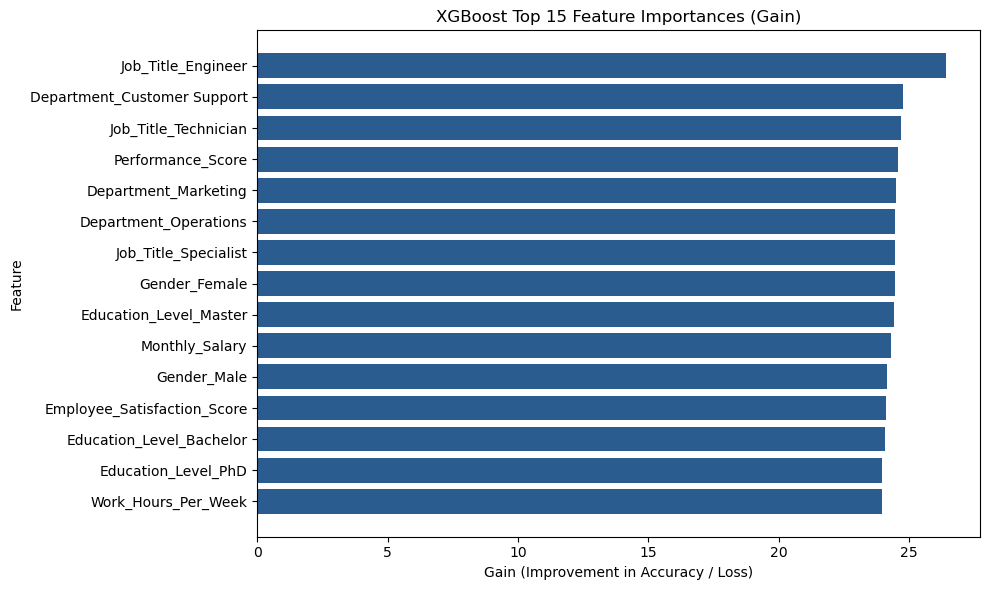

In [7]:
# Fit full development model for interpretability
full_adapter = adapter_factory()
full_adapter.fit(X=dev_df[feature_cols], y=dev_df[target_col])

xgb_model = full_adapter._model
fitted_feature_names = full_adapter._fitted_columns

# Extract gain and weight importances
booster = xgb_model.get_booster()
score_gain = booster.get_score(importance_type="gain")
score_weight = booster.get_score(importance_type="weight")

importance_data = []
for feat in fitted_feature_names:
    importance_data.append({
        "feature": feat,
        "gain": score_gain.get(feat, 0.0),
        "weight": score_weight.get(feat, 0.0),
    })

importance_df = pd.DataFrame(importance_data).sort_values("gain", ascending=False).reset_index(drop=True)

print("Top 10 Features by Gain:")
display(importance_df.head(10))

# Plot Feature Importances
plt.figure(figsize=(10, 6))
top_feats = importance_df.head(15)
plt.barh(top_feats["feature"][::-1], top_feats["gain"][::-1], color="#2b5c8f")
plt.xlabel("Gain (Improvement in Accuracy / Loss)")
plt.ylabel("Feature")
plt.title("XGBoost Top 15 Feature Importances (Gain)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure_01_xgboost_feature_importance.png", dpi=300)
plt.show()

## 15. Plots & Artifact Serialization

Generate Precision-Recall curve, Confusion Matrix plot, and serialize all outputs into `results/models/xgboost/`.

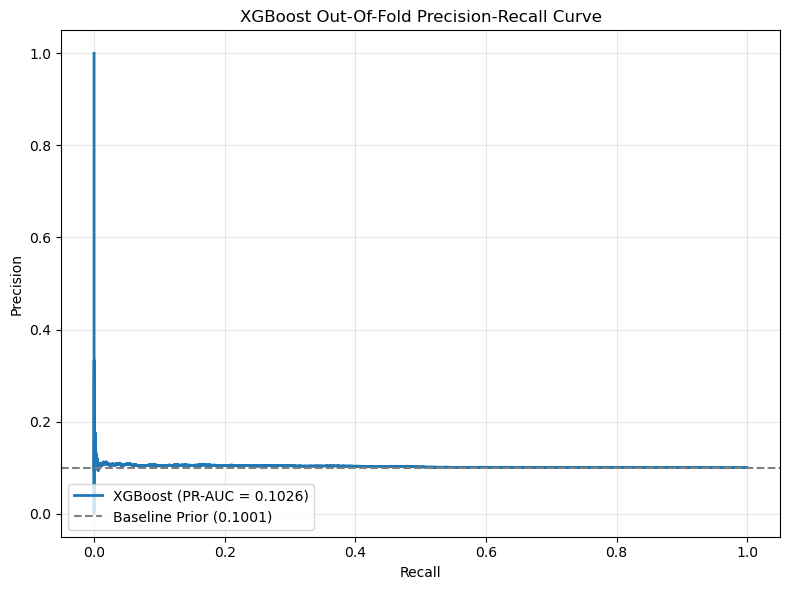

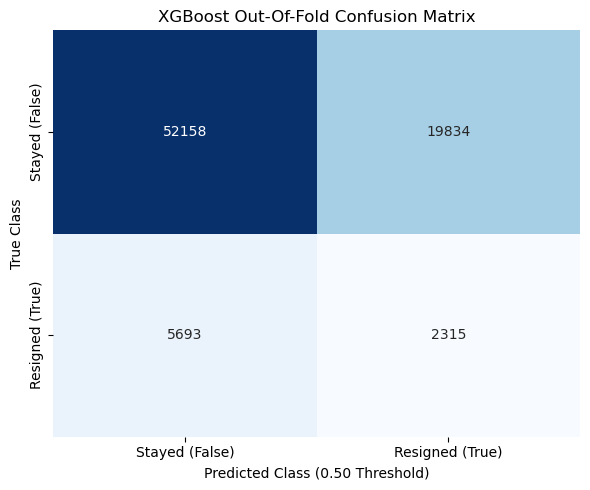

All XGBoost artifacts successfully serialized to: C:\Users\USER\Desktop\AIML projects\Employee_Resignation_Prediction\results\models\xgboost


In [8]:
# 1. Precision-Recall Curve Plot
precisions, recalls, thresholds = precision_recall_curve(
    oof_preds["y_true"], oof_preds["y_probability"]
)
ap_score = summary_metrics["pooled_average_precision"]

plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color="#1f77b4", lw=2, label=f"XGBoost (PR-AUC = {ap_score:.4f})")
plt.axhline(y=dev_df[target_col].mean(), color="gray", linestyle="--", label=f"Baseline Prior ({dev_df[target_col].mean():.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("XGBoost Out-Of-Fold Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "pr_curve_xgboost.png", dpi=300)
plt.savefig(RESULTS_DIR / "figure_02_xgboost_pr_curve.png", dpi=300)
plt.show()

# 2. Confusion Matrix Plot
cm = confusion_matrix(oof_preds["y_true"], oof_preds["y_pred_0_5"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Stayed (False)", "Resigned (True)"],
            yticklabels=["Stayed (False)", "Resigned (True)"])
plt.xlabel("Predicted Class (0.50 Threshold)")
plt.ylabel("True Class")
plt.title("XGBoost Out-Of-Fold Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix_xgboost.png", dpi=300)
plt.savefig(RESULTS_DIR / "figure_03_xgboost_confusion_matrix.png", dpi=300)
plt.show()

# 3. Serialize CSV and JSON Artifacts
oof_preds.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)
oof_preds.to_csv(RESULTS_DIR / "xgboost_oof_predictions.csv", index=False)
fold_metrics_df.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)
fold_metrics_df.to_csv(RESULTS_DIR / "xgboost_fold_metrics.csv", index=False)
importance_df.to_csv(RESULTS_DIR / "feature_importances.csv", index=False)

with open(RESULTS_DIR / "summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)

with open(RESULTS_DIR / "xgboost_summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)

print("All XGBoost artifacts successfully serialized to:", RESULTS_DIR)

## 16. Summary & Readiness

The XGBoost model pipeline has been executed with strict 5-fold cross-validation and fold-local one-hot encoding.
- **Pooled PR-AUC (Average Precision):** `0.10263`
- **Pooled ROC-AUC:** `0.50613`
- **Pooled Brier Score:** `0.21857`
- **Total Development Records:** 80,000 (100% verified OOF coverage)
- **Formal Holdout:** Permanently quarantined (0 records exposed).

Ready for Stage 11 Multi-Model Benchmarking.